<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula25d%20-%20normal%20equation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

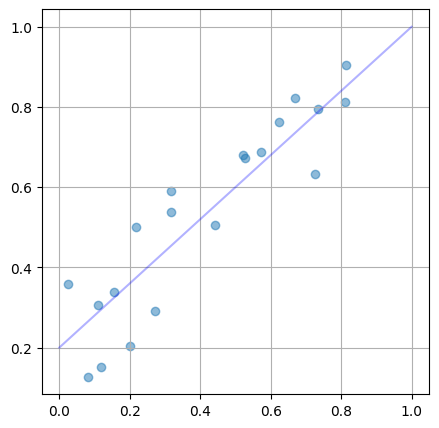

In [186]:
import numpy as np
from matplotlib import pyplot as plt

def create_regression_dataset(n=20, coefs=[1], intercept=-1):
  X = np.random.rand(n, 1)
  noise = np.random.randn(n, 1) * 0.1
  y = X * coefs + intercept + noise
  return X, y

def plot_dataset(X, y):
  plt.scatter(X[:,0], y, alpha=0.5)
  plt.grid(True)

def plot_line(coefs, intercept, color="green"):
  xs = np.array([0,1])
  ys = coefs * xs + intercept
  plt.plot(xs, ys, c=color, alpha=0.3)

coefs = [0.8]
intercept = 0.2
X, y = create_regression_dataset(20, coefs, intercept)

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plt.show()

rmse: 0.09658204571887477
coefs: [0.83475169]		intercept: 0.18935393836137526


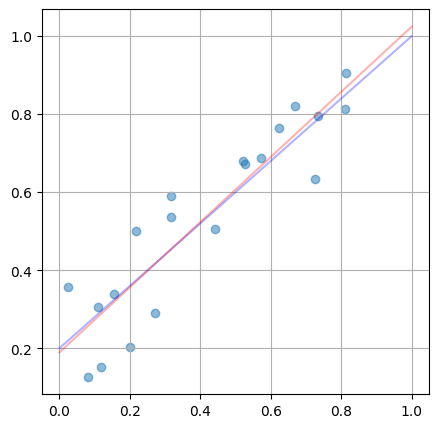

In [196]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import root_mean_squared_error

def include_bias(X):
  return np.hstack([np.ones((X.shape[0], 1)), X])

class NormalEquation(BaseEstimator, ClassifierMixin):
  def fit(self, X, y):
    X = include_bias(X)
    y = y.reshape(-1)
    self.w = np.linalg.pinv(X) @ y
    return self

  def predict(self, X):
    X = include_bias(X)
    return X @ self.w

model = NormalEquation()
model.fit(X, y)
y_pred = model.predict(X)
print(f"rmse: {root_mean_squared_error(y, y_pred)}")
print(f"coefs: {model.w[1:]}\t\tintercept: {model.w[0]}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_line(coefs, intercept, color="blue")
plot_line(model.w[1:], model.w[0], color="red")
plt.show()

rmse: 0.10637600665768303


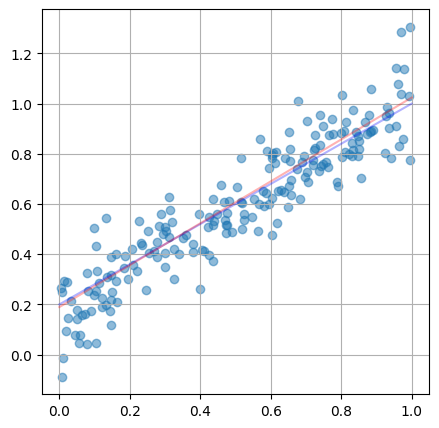

In [198]:
X_test, y_test = create_regression_dataset(200, coefs, intercept)
y_pred = model.predict(X_test)
print(f"rmse: {root_mean_squared_error(y_test, y_pred)}")

plt.figure(figsize=(5, 5))
plot_dataset(X_test, y_test)
plot_line(coefs, intercept, color="blue")
plot_line(model.w[1:], model.w[0], color="red")
plt.show()